#  Road Damage Detection: Evaluation & Comparison

**Objective:** compare the three baseline models (YOLOv8s, YOLO11s, YOLO26s) on the held-out **test set**, evaluated once.

**Protocol:**
- Same data, image size (640), batch size and device for all models.
- The test set is used for reporting only; no model or setting is selected based on it.
- Tuning experiments (E1, E2) were decided on the validation set and are not re-evaluated here.

In [1]:
from pathlib import Path

for path in Path("/kaggle/input").rglob("*.pt"):
    print(path)


/kaggle/input/datasets/osmanahmedosman/road-damage-weights/yolo11s_best.pt
/kaggle/input/datasets/osmanahmedosman/road-damage-weights/yolo26s_best.pt
/kaggle/input/datasets/osmanahmedosman/road-damage-weights/yolov8s_best.pt


In [2]:
from pathlib import Path

for p in Path("/kaggle/input/datasets/osmanahmedosman").iterdir():
    print(p)


/kaggle/input/datasets/osmanahmedosman/road-damage-weights
/kaggle/input/datasets/osmanahmedosman/road-damage-detection-cleaned-dataset


In [3]:
!pip install -q -U ultralytics

import os, shutil, time, yaml, torch
import pandas as pd
from pathlib import Path
from ultralytics import YOLO

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU: Tesla T4


In [4]:
WEIGHTS_DIR = Path("/kaggle/input/datasets/osmanahmedosman/road-damage-weights")

WEIGHTS = {
    "yolov8s": WEIGHTS_DIR / "yolov8s_best.pt",
    "yolo11s": WEIGHTS_DIR / "yolo11s_best.pt",
    "yolo26s": WEIGHTS_DIR / "yolo26s_best.pt",
}

for name, path in WEIGHTS.items():
    assert path.exists(), f"Missing weights: {path}"
    print(name, "->", path.name)

yolov8s -> yolov8s_best.pt
yolo11s -> yolo11s_best.pt
yolo26s -> yolo26s_best.pt


In [5]:
BASE = Path("/kaggle/working")
INPUT_DIR = Path("/kaggle/input/datasets/osmanahmedosman/road-damage-detection-cleaned-dataset/road_damage_clean")
CLEAN_DIR = BASE / "road_damage_clean"
RUNS_DIR = str(BASE / "eval_runs")

if not CLEAN_DIR.exists():
    shutil.copytree(INPUT_DIR, CLEAN_DIR)

cfg = yaml.safe_load(open(CLEAN_DIR / "data.yaml"))
cfg["path"] = str(CLEAN_DIR)
with open(CLEAN_DIR / "data.yaml", "w") as f:
    yaml.dump(cfg, f, sort_keys=False)

n_img = len(list((CLEAN_DIR / "test" / "images").iterdir()))
n_lbl = len(list((CLEAN_DIR / "test" / "labels").iterdir()))
assert n_img == n_lbl == 667, f"test split unexpected: {n_img} images / {n_lbl} labels"
print("Test set:", n_img, "images /", n_lbl, "labels")

Test set: 667 images / 667 labels


In [6]:
test_results = {}

for name, path in WEIGHTS.items():
    model = YOLO(str(path))
    test_results[name] = model.val(
        data=str(CLEAN_DIR / "data.yaml"),
        split="test",
        imgsz=640,
        batch=16,
        device=0,
        project=RUNS_DIR,
        name=f"test_{name}",
        exist_ok=True,
        plots=True,
        verbose=False,
    )
    print(name, "done")

Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1907.2±866.3 MB/s, size: 86.2 KB)
val: Scanning /kaggle/working/road_damage_clean/test/labels... 667 images, 0 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 667/667 1.1Kit/s 0.6s<0.1s
val: /kaggle/working/road_damage_clean/test/images/img-921-_jpg.rf.8f8ff0506e35b6530daaccf4e3464eba.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: New cache created: /kaggle/working/road_damage_clean/test/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 10, len(boxes) = 2025. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP5

In [7]:
rows = []
for name, r in test_results.items():
    b = r.box
    p, rec = b.mp, b.mr
    rows.append({
        "model": name,
        "mAP50": b.map50,
        "mAP50-95": b.map,
        "precision": p,
        "recall": rec,
        "F1": 2 * p * rec / (p + rec),
    })

summary = pd.DataFrame(rows).set_index("model").round(3)
summary

,mAP50,mAP50-95,precision,recall,F1
model,,,,,
yolov8s,0.528,0.315,0.628,0.488,0.549
yolo11s,0.524,0.306,0.575,0.510,0.540
yolo26s,0.564,0.338,0.651,0.518,0.577


In [8]:
class_names = list(next(iter(test_results.values())).names.values())

per_class = pd.DataFrame(
    {name: r.box.maps for name, r in test_results.items()},
    index=class_names,
).round(3)
per_class

,yolov8s,yolo11s,yolo26s
alligator,0.156,0.146,0.161
block,0.654,0.615,0.646
crack,0.306,0.321,0.368
longitudinal,0.114,0.102,0.141
pothole,0.329,0.332,0.340
transverse,0.328,0.318,0.370


In [9]:
rows = []
for name, path in WEIGHTS.items():
    m = YOLO(str(path))
    n_params = sum(p.numel() for p in m.model.parameters())
    rows.append({
        "model": name,
        "params_M": n_params / 1e6,
        "weights_MB": os.path.getsize(path) / 1e6,
    })

size_df = pd.DataFrame(rows).set_index("model").round(2)
size_df

,params_M,weights_MB
model,,
yolov8s,11.14,22.52
yolo11s,9.43,19.18
yolo26s,9.95,20.32


In [10]:
OUT = Path("/kaggle/working/eval_results")
OUT.mkdir(exist_ok=True)

summary.to_csv(OUT / "test_summary.csv")
per_class.to_csv(OUT / "test_per_class.csv")
size_df.to_csv(OUT / "model_size.csv")

shutil.make_archive("/kaggle/working/eval_part1", "zip", "/kaggle/working", "eval_results")
shutil.make_archive("/kaggle/working/eval_plots", "zip", RUNS_DIR)
print(os.listdir("/kaggle/working"))

['eval_runs', 'road_damage_clean', 'eval_part1.zip', '.virtual_documents', 'eval_results', 'eval_plots.zip']


### Results & Interpretation: Test-Set Comparison (baselines, evaluated once)
| Model | mAP50 | mAP50-95 | P | R | F1 |
|---|---|---|---|---|---|
| YOLOv8s | 0.528 | 0.315 | 0.628 | 0.488 | 0.549 |
| YOLO11s | 0.524 | 0.306 | 0.575 | 0.510 | 0.540 |
| **YOLO26s** | **0.564** | **0.338** | **0.651** | **0.518** | **0.577** |

- **YOLO26s ranks first** on both validation and test (+0.023 to +0.032 mAP50-95 over the others); the gap is concentrated in thin-crack classes (`crack`, `transverse`, `longitudinal`).
- **YOLOv8s and YOLO11s are not distinguishable**: their order flips between validation and test.
- **Test scores are slightly above validation**, driven mostly by `transverse` (58 test instances); we read this as small-sample noise, not better generalization.
- `alligator` (0.15 to 0.16) and `longitudinal` (0.10 to 0.14) remain the weakest classes for all models.

**Limits:** one training run per model (no variance estimate); small per-class test sets (`block` 46, `transverse` 58 instances); P/R are reported at each model's own best-F1 threshold, so mAP is the more reliable comparison; 666 of 667 test images were evaluated (cause not investigated).

In [11]:
import numpy as np

test_imgs = [str(p) for p in sorted((CLEAN_DIR / "test" / "images").iterdir())]

def benchmark(weights, device, imgs, n_warmup=10, conf=0.25):
    model = YOLO(str(weights))
    for p in imgs[:n_warmup]:                       # warm-up: not timed
        model.predict(p, device=device, imgsz=640, conf=conf, verbose=False)
    t = []
    for p in imgs[n_warmup:]:
        s = model.predict(p, device=device, imgsz=640, conf=conf, verbose=False)[0].speed
        t.append(s["preprocess"] + s["inference"] + s["postprocess"])
    t = np.array(t)
    return {"ms": t.mean(), "p95_ms": np.percentile(t, 95), "fps": 1000 / t.mean()}

speed_rows = []
for name, path in WEIGHTS.items():
    g = benchmark(path, 0, test_imgs[:210])         # 200 timed images on GPU
    c = benchmark(path, "cpu", test_imgs[:110])     # 100 timed images on CPU
    speed_rows.append({"model": name, "GPU_ms": g["ms"], "GPU_FPS": g["fps"],
                       "CPU_ms": c["ms"], "CPU_FPS": c["fps"]})

speed_df = pd.DataFrame(speed_rows).set_index("model").round(1)
speed_df

,GPU_ms,GPU_FPS,CPU_ms,CPU_FPS
model,,,,
yolov8s,10.1,98.6,207.7,4.8
yolo11s,10.0,100.4,171.9,5.8
yolo26s,11.9,84.3,177.6,5.6


In [14]:
from collections import Counter

cols = Counter()
bad_files = set()
for split in ["train", "valid", "test"]:
    for lbl in (CLEAN_DIR / split / "labels").glob("*.txt"):
        for line in lbl.read_text().splitlines():
            n = len(line.split())
            if n == 0:
                continue
            cols[(split, n)] += 1
            if n != 5:
                bad_files.add((split, lbl.name))

print(sorted(cols.items()))
print("files with non-5-column lines:", len(bad_files))

sample = CLEAN_DIR / "test" / "labels" / "img-532-_jpg.rf.4cc7e7771197add0d3d8a72126c445c4.txt"
print(sample.read_text()[:300])

[(('test', 5), 2016), (('test', 15), 1), (('test', 17), 1), (('test', 21), 1), (('test', 25), 3), (('test', 27), 1), (('test', 29), 1), (('test', 39), 2), (('test', 43), 1), (('test', 63), 1), (('train', 5), 14778), (('train', 11), 8), (('train', 13), 6), (('train', 15), 9), (('train', 17), 7), (('train', 19), 6), (('train', 21), 4), (('train', 23), 5), (('train', 25), 2), (('train', 27), 2), (('train', 29), 4), (('train', 31), 3), (('train', 33), 1), (('train', 37), 2), (('train', 45), 1), (('train', 47), 1), (('train', 49), 1), (('train', 53), 1), (('train', 59), 1), (('train', 67), 1), (('train', 85), 1), (('valid', 5), 3715), (('valid', 15), 1), (('valid', 19), 2), (('valid', 29), 1), (('valid', 33), 2), (('valid', 45), 1)]
files with non-5-column lines: 35
2 0.36044973593749996 0.14384920625 0.44312169375000005 0.146329365625 0.5985449734375 0.15625 0.68121693125 0.1512896828125 0.7771164015625 0.1612103171875 0.8664021156249999 0.15873015937499999 0.9953703703125001 0.18601190468

In [15]:
def load_gt(lbl):
    rows = []
    for line in lbl.read_text().splitlines():
        v = line.split()
        if not v:
            continue
        cls, vals = float(v[0]), np.array(v[1:], dtype=float)
        if len(vals) == 4:
            xc, yc, w, h = vals
        else:
            assert len(vals) % 2 == 0, f"odd polygon length in {lbl.name}"
            xs, ys = vals[0::2], vals[1::2]
            w, h = xs.max() - xs.min(), ys.max() - ys.min()
            xc, yc = (xs.max() + xs.min()) / 2, (ys.max() + ys.min()) / 2
        rows.append([cls, xc, yc, w, h])
    return np.array(rows).reshape(-1, 5)

In [17]:
def xywhn_to_xyxy(a):
    return np.stack([a[:,0]-a[:,2]/2, a[:,1]-a[:,3]/2,
                     a[:,0]+a[:,2]/2, a[:,1]+a[:,3]/2], axis=1)

def iou_matrix(a, b):
    x1 = np.maximum(a[:,None,0], b[None,:,0]); y1 = np.maximum(a[:,None,1], b[None,:,1])
    x2 = np.minimum(a[:,None,2], b[None,:,2]); y2 = np.minimum(a[:,None,3], b[None,:,3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:,2]-a[:,0]) * (a[:,3]-a[:,1])
    area_b = (b[:,2]-b[:,0]) * (b[:,3]-b[:,1])
    return inter / (area_a[:,None] + area_b[None,:] - inter + 1e-9)

def match_split(weights, split="test", conf=0.25, iou_thr=0.5):
    model = YOLO(str(weights))
    matched_ious, tp, fp, n_gt = [], 0, 0, 0
    for img in sorted((CLEAN_DIR / split / "images").iterdir()):
        lbl = CLEAN_DIR / split / "labels" / f"{img.stem}.txt"
        gt = load_gt(lbl)
        g_cls, g_box = gt[:,0].astype(int), xywhn_to_xyxy(gt[:,1:5])
        n_gt += len(gt)

        r = model.predict(str(img), conf=conf, imgsz=640, device=0, verbose=False)[0]
        p_box = r.boxes.xyxyn.cpu().numpy()
        p_cls = r.boxes.cls.cpu().numpy().astype(int)
        order = np.argsort(-r.boxes.conf.cpu().numpy())      # highest confidence first
        p_box, p_cls = p_box[order], p_cls[order]

        M = iou_matrix(p_box, g_box) if len(p_box) and len(g_box) else np.zeros((len(p_box), len(g_box)))
        used = set()
        for i in range(len(p_box)):
            best_j, best_iou = -1, 0.0
            for j in range(len(g_box)):
                if j not in used and g_cls[j] == p_cls[i] and M[i, j] > best_iou:
                    best_j, best_iou = j, M[i, j]
            if best_iou >= iou_thr:
                used.add(best_j); matched_ious.append(best_iou); tp += 1
            else:
                fp += 1

    ious = np.array(matched_ious)
    return {"n_gt": n_gt, "TP": tp, "FP": fp, "FN": n_gt - tp,
            "precision@0.25": tp / (tp + fp), "recall@0.25": tp / n_gt,
            "mean_IoU_TP": ious.mean(), "median_IoU_TP": np.median(ious)}

iou_rows = {name: match_split(path) for name, path in WEIGHTS.items()}
iou_df = pd.DataFrame(iou_rows).T.round(3)
iou_df

,n_gt,TP,FP,FN,precision@0.25,recall@0.25,mean_IoU_TP,median_IoU_TP
yolov8s,2028.0,831.0,494.0,1197.0,0.627,0.410,0.770,0.790
yolo11s,2028.0,776.0,412.0,1252.0,0.653,0.383,0.778,0.794
yolo26s,2028.0,823.0,405.0,1205.0,0.670,0.406,0.779,0.791


In [18]:
onnx_paths = {}
for name, path in WEIGHTS.items():
    local_pt = Path("/kaggle/working") / f"{name}.pt"
    shutil.copy(path, local_pt)                       # /kaggle/input is read-only
    exported = YOLO(str(local_pt)).export(format="onnx", imgsz=640, device="cpu")
    onnx_paths[name] = Path(exported)

onnx_rows = []
for name, p in onnx_paths.items():
    b = benchmark(p, "cpu", test_imgs[:110])
    onnx_rows.append({"model": name, "ONNX_MB": os.path.getsize(p) / 1e6,
                      "ONNX_CPU_ms": b["ms"], "ONNX_CPU_FPS": b["fps"]})

onnx_df = pd.DataFrame(onnx_rows).set_index("model").round(1)
onnx_df

Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 72 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs

PyTorch: starting from '/kaggle/working/yolov8s.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 10, 8400) (21.5 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 12 packages in 405ms
Prepared 2 packages in 320ms
Installed 2 packages in 13ms
 + onnxruntime==1.31.1
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 1.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.22.0 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 4.4s, saved as '/kaggle/worki

,ONNX_MB,ONNX_CPU_ms,ONNX_CPU_FPS
model,,,
yolov8s,44.8,180.3,5.5
yolo11s,37.9,149.2,6.7
yolo26s,38.2,150.4,6.7


Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,467,502 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1771.1±435.3 MB/s, size: 87.6 KB)
val: Scanning /kaggle/working/road_damage_clean/test/labels.cache... 667 images, 0 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 667/667 186.5Mit/s 0.0s
val: /kaggle/working/road_damage_clean/test/images/img-921-_jpg.rf.8f8ff0506e35b6530daaccf4e3464eba.jpg: ignoring corrupt image/label: labels mix segment and detection rows
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 10, len(boxes) = 2025. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 42/42 4.0it/s 10.4s0.2s
                   all

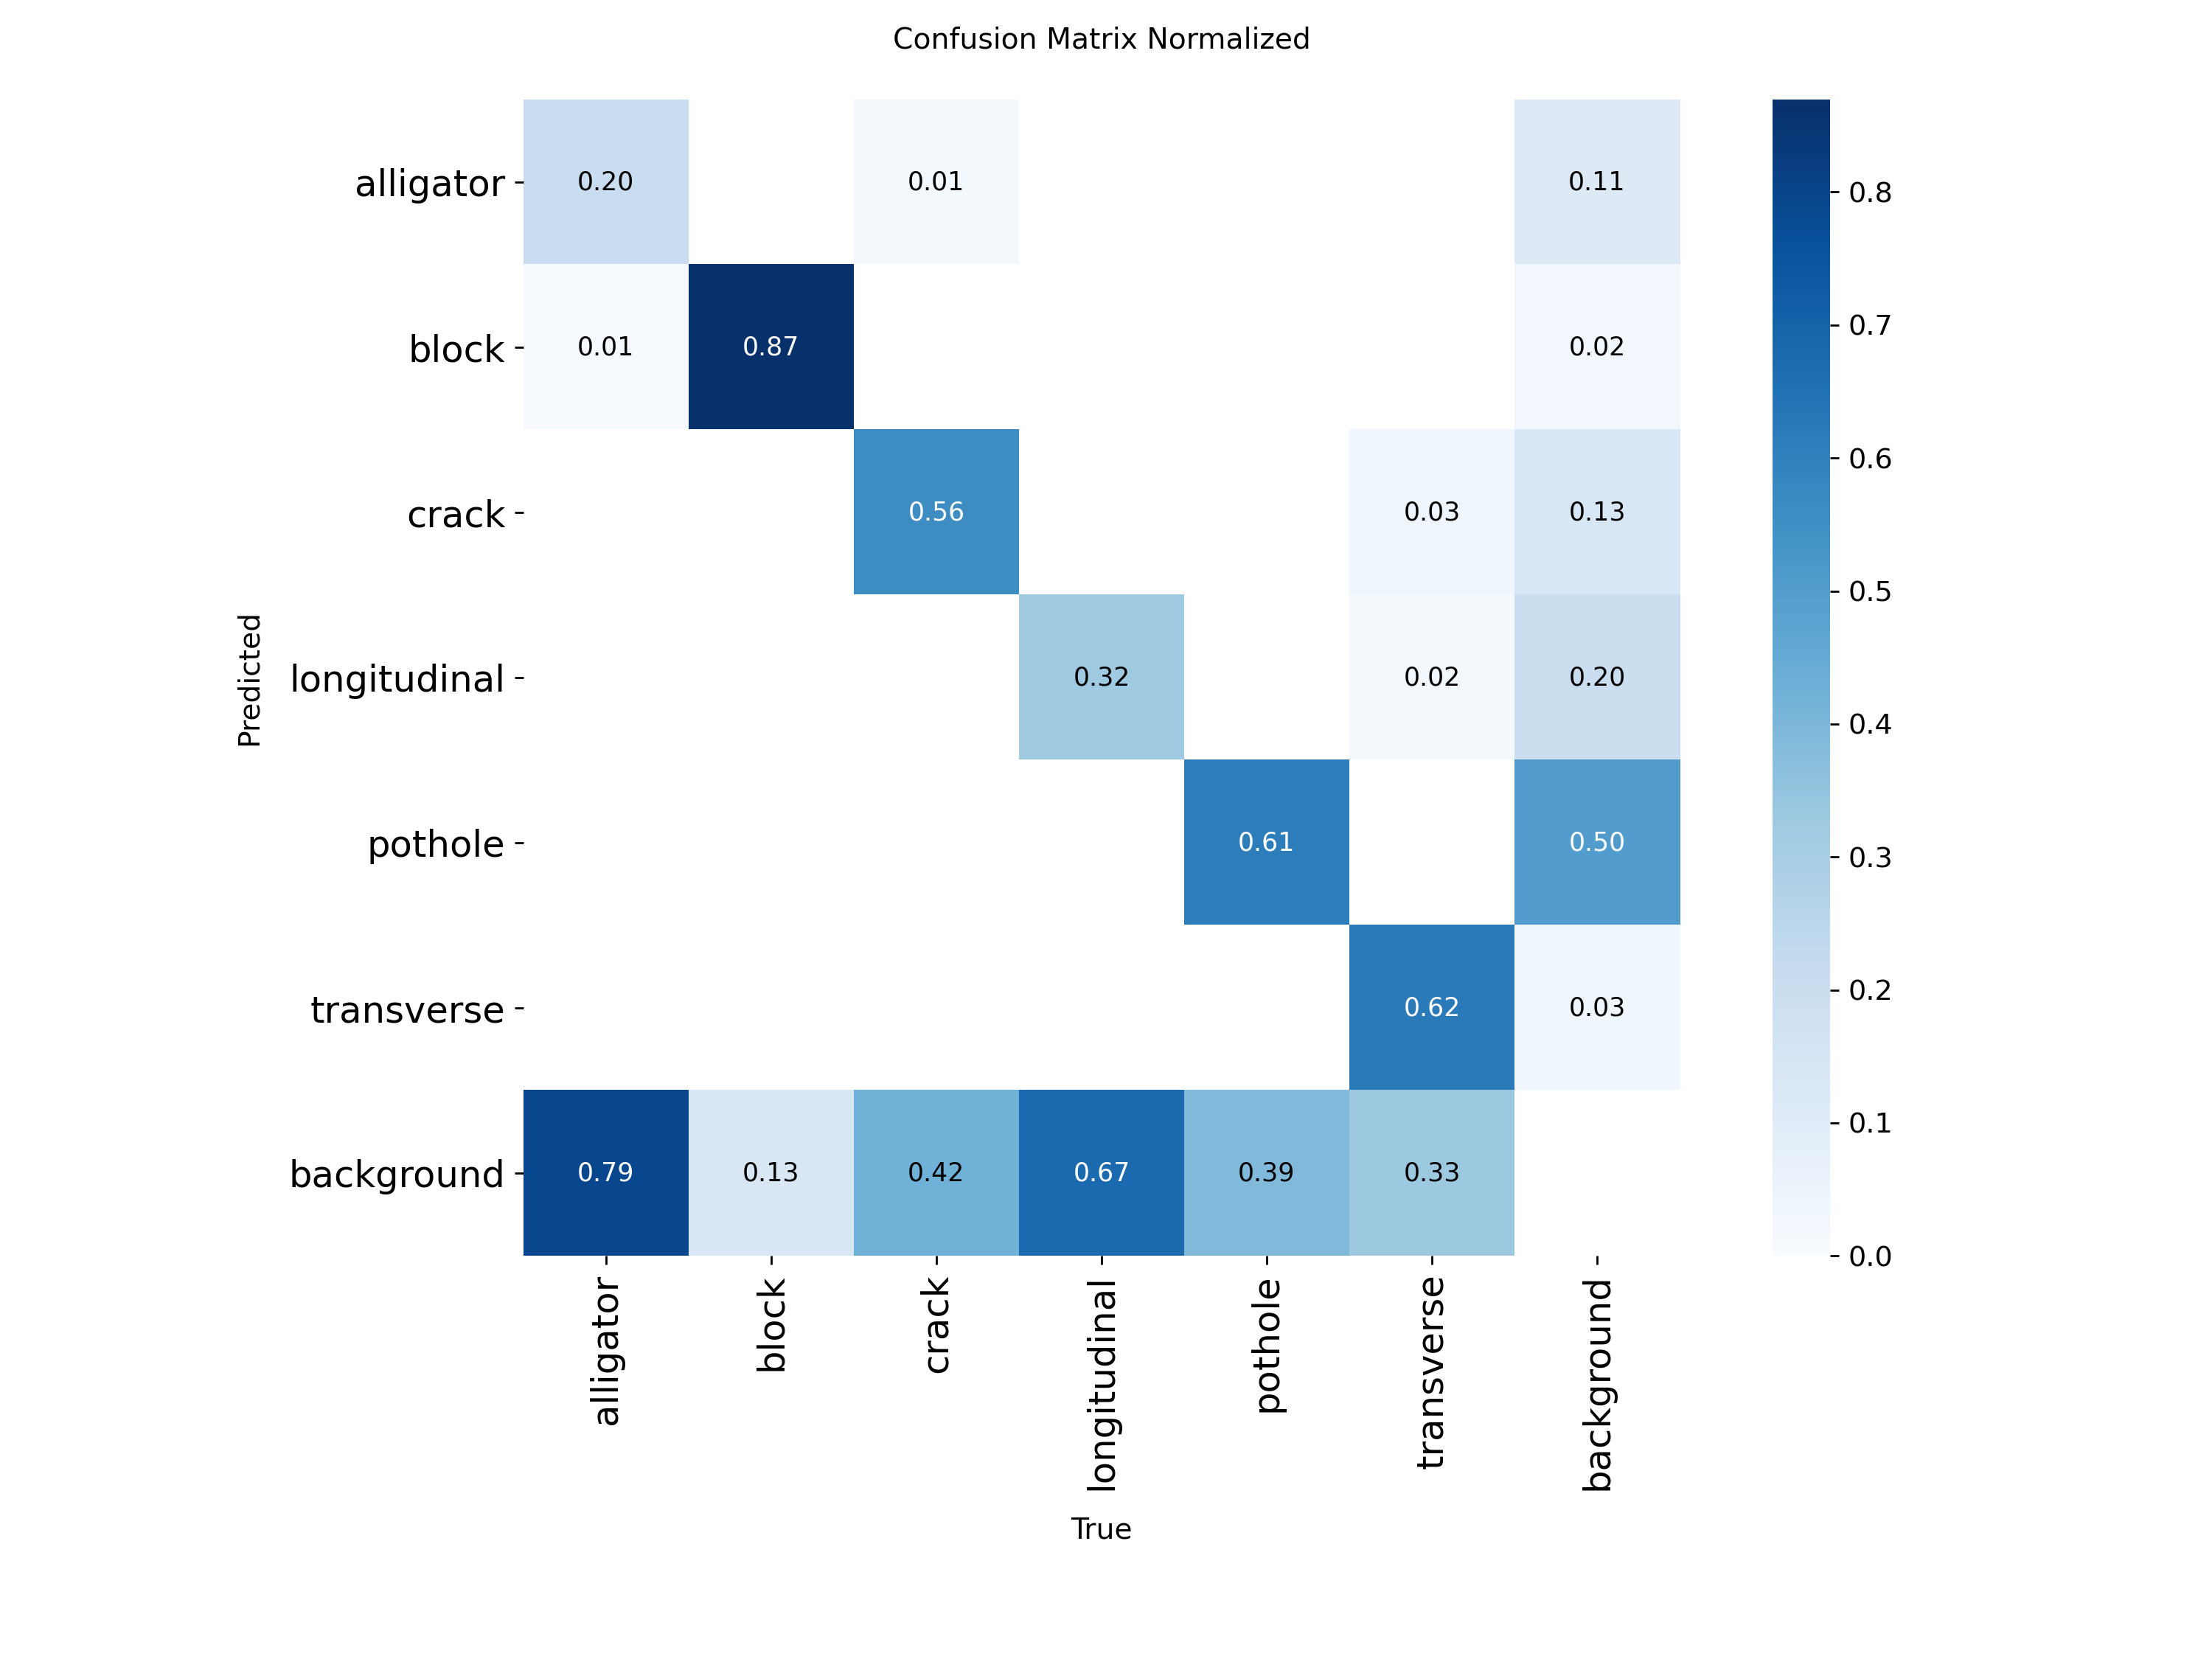

In [19]:
from IPython.display import Image, display

m = YOLO(str(WEIGHTS["yolo26s"]))
m.val(data=str(CLEAN_DIR / "data.yaml"), split="test", imgsz=640, batch=16, device=0,
      conf=0.25, project=RUNS_DIR, name="test_yolo26s_conf025",
      exist_ok=True, plots=True, verbose=False)

display(Image(filename=f"{RUNS_DIR}/test_yolo26s_conf025/confusion_matrix_normalized.png"))

In [21]:
final = (summary.join(size_df).join(speed_df).join(onnx_df)
         .join(iou_df[["precision@0.25", "recall@0.25", "mean_IoU_TP"]]))
final

,mAP50,mAP50-95,precision,recall,F1,params_M,weights_MB,GPU_ms,GPU_FPS,CPU_ms,CPU_FPS,ONNX_MB,ONNX_CPU_ms,ONNX_CPU_FPS,precision@0.25,recall@0.25,mean_IoU_TP
model,,,,,,,,,,,,,,,,,
yolov8s,0.528,0.315,0.628,0.488,0.549,11.14,22.52,10.1,98.6,207.7,4.8,44.8,180.3,5.5,0.627,0.410,0.770
yolo11s,0.524,0.306,0.575,0.510,0.540,9.43,19.18,10.0,100.4,171.9,5.8,37.9,149.2,6.7,0.653,0.383,0.778
yolo26s,0.564,0.338,0.651,0.518,0.577,9.95,20.32,11.9,84.3,177.6,5.6,38.2,150.4,6.7,0.670,0.406,0.779


In [20]:
iou_df.to_csv(OUT / "iou_tp_fp.csv")
speed_df.to_csv(OUT / "speed.csv")
onnx_df.to_csv(OUT / "onnx.csv")
final.to_csv(OUT / "final_comparison.csv")

shutil.make_archive("/kaggle/working/eval_part2", "zip", "/kaggle/working", "eval_results")
shutil.make_archive("/kaggle/working/eval_plots", "zip", RUNS_DIR)
print(os.listdir("/kaggle/working"))

['eval_part2.zip', 'yolo11s.pt', 'yolo11s.onnx', 'yolov8s.onnx', 'eval_runs', 'road_damage_clean', 'yolov8s.pt', 'yolo26s.onnx', 'eval_part1.zip', '.virtual_documents', 'eval_results', 'yolo26s.pt', 'eval_plots.zip']


### Results & Interpretation: Final Comparison (test set, baselines)

**Accuracy**
| Model | mAP50 | mAP50-95 | P | R | F1 | P@0.25 | R@0.25 | Mean IoU (TP) |
|---|---|---|---|---|---|---|---|---|
| YOLOv8s | 0.528 | 0.315 | 0.628 | 0.488 | 0.549 | 0.627 | 0.410 | 0.770 |
| YOLO11s | 0.524 | 0.306 | 0.575 | 0.510 | 0.540 | 0.653 | 0.383 | 0.778 |
| **YOLO26s** | **0.564** | **0.338** | **0.651** | **0.518** | **0.577** | **0.670** | 0.406 | 0.779 |

**Efficiency** (NVIDIA T4 on Kaggle; CPU = Kaggle CPU)
| Model | Params (fused) | GFLOPs | .pt | ONNX | GPU ms (FPS) | CPU ms PyTorch (FPS) | CPU ms ONNX (FPS) |
|---|---|---|---|---|---|---|---|
| YOLOv8s | 11.13M | 28.4 | 22.5 MB | 44.8 MB | 10.1 (98.6) | 207.7 (4.8) | 180.3 (5.5) |
| YOLO11s | 9.42M | 21.4 | 19.2 MB | 37.9 MB | 10.0 (100.4) | 171.9 (5.8) | 149.2 (6.7) |
| YOLO26s | 9.47M | 20.8 | 20.3 MB | 38.2 MB | 11.9 (84.3) | 177.6 (5.6) | 150.4 (6.7) |

- **YOLO26s is selected.** It has the highest mAP on validation and test, and the fewest false positives at conf 0.25 (405 vs 494 / 412). Its true-positive count is similar to YOLOv8s (823 vs 831), so the gain comes from confidence ranking rather than finding more objects.
- **Localization quality is equal** across models (mean IoU of matched boxes 0.77 to 0.78); this metric only covers detections with IoU ≥ 0.5, so it cannot go below 0.5 by construction.
- **Confusion matrix** (conf ≈ 0.001, YOLO26s, test): confusion between damage classes is minimal (largest off-diagonal cell: 17 of 2,025). The main failure mode is separating damage from background: `alligator` accounts for 38% of background false positives, followed by `pothole` (23.5%) and `longitudinal` (19.4%); the same pattern appears on validation.
- **Deployment:** all models run at ≈ 85 to 100 FPS on a T4 but only ≈ 5 to 7 FPS on CPU; ONNX is 13 to 15% faster than PyTorch on CPU. Real-time video on CPU therefore requires frame skipping or lower resolution.

**Limits:** one training run per model (no variance estimate); small per-class test sets (`block` 46, `transverse` 58 instances); speed measured once per model on a shared cloud machine (absolute values vary between runs, only the relative comparison is reliable); ONNX accuracy parity with the PyTorch weights was not verified; the confusion matrix reflects a near-zero confidence threshold, not deployment settings.

### ✅ Checkpoint: Evaluation
- [x] Three baselines evaluated once on the test set (mAP, P/R, IoU, speed, size, ONNX)
- [x] Final model: YOLO26s
- **Needed next:** per-class confidence thresholds (from validation) and the deployment app

In [22]:
import numpy as np, json

m = YOLO(str(WEIGHTS["yolo26s"]))
rv = m.val(data=str(CLEAN_DIR / "data.yaml"), imgsz=640, batch=16, device=0,
           project=RUNS_DIR, name="val_yolo26s_thr", exist_ok=True,
           plots=False, verbose=False)

px = rv.box.px
f1 = rv.box.f1_curve
names = [rv.names[i] for i in rv.box.ap_class_index]

def smooth(y, k=51):
    pad = k // 2
    yp = np.pad(y, pad, mode="edge")
    return np.convolve(yp, np.ones(k) / k, mode="valid")

thresholds = {}
for i, cname in enumerate(names):
    s = smooth(f1[i])
    j = int(s.argmax())
    thresholds[cname] = {"conf": round(float(px[j]), 3), "f1": round(float(s[j]), 3)}

for c, v in thresholds.items():
    print(f"{c:13s} conf={v['conf']:.3f}  F1={v['f1']:.3f}")

json.dump({c: v["conf"] for c, v in thresholds.items()},
          open(OUT / "class_thresholds.json", "w"), indent=2)

Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,467,502 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1254.2±565.9 MB/s, size: 79.1 KB)
val: Scanning /kaggle/working/road_damage_clean/valid/labels... 1238 images, 0 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 1238/1238 1.2Kit/s 1.1s0.1s
val: /kaggle/working/road_damage_clean/valid/images/img-892-_jpg.rf.6eba1885d9664c0cc31e7d1ec0f35d62.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: New cache created: /kaggle/working/road_damage_clean/valid/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 5, len(boxes) = 3719. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pathlib import Path

sns.set_theme(style="whitegrid")

OUT = Path("/kaggle/working/eval_results")
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

final = pd.read_csv(OUT / "final_comparison.csv", index_col="model")
per_class = pd.read_csv(OUT / "test_per_class.csv", index_col=0)
iou_df = pd.read_csv(OUT / "iou_tp_fp.csv", index_col=0)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

final[["mAP50", "mAP50-95"]]

,mAP50,mAP50-95
model,,
yolov8s,0.528,0.315
yolo11s,0.524,0.306
yolo26s,0.564,0.338


## Visual Comparison (test set)

## Figure 1 (mAP)

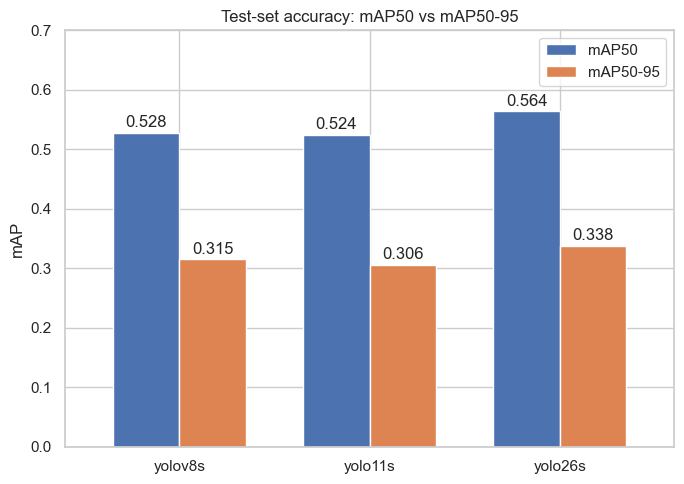

In [43]:
ax = final[["mAP50", "mAP50-95"]].plot(kind="bar", figsize=(7, 5), width=0.7, rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", padding=2)
ax.set_ylim(0, 0.7)
ax.set_ylabel("mAP")
ax.set_xlabel("")
ax.set_title("Test-set accuracy: mAP50 vs mAP50-95")
save_fig("01_map_comparison")

## Figure 2 (per class)

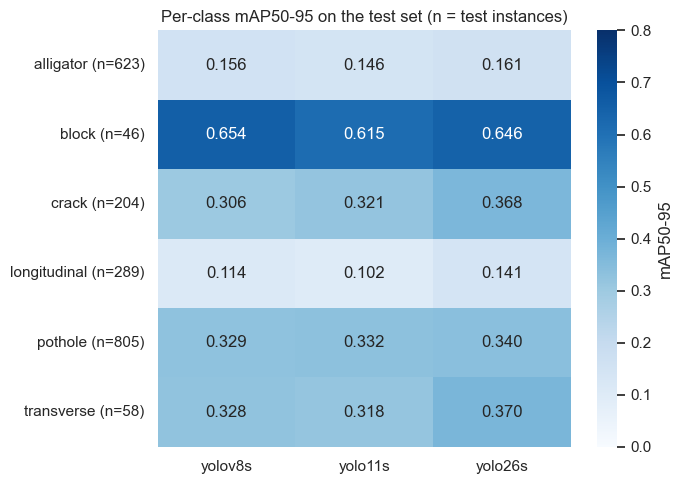

In [42]:
TEST_N = {"alligator": 623, "block": 46, "crack": 204,
          "longitudinal": 289, "pothole": 805, "transverse": 58}

pc = per_class.copy()
pc.index = [f"{c} (n={TEST_N[c]})" for c in pc.index]

plt.figure(figsize=(7, 5))
sns.heatmap(pc, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=0.8,
            cbar_kws={"label": "mAP50-95"})
plt.title("Per-class mAP50-95 on the test set (n = test instances)")
save_fig("02_per_class_heatmap")

## Figure 3 (P/R/F1)

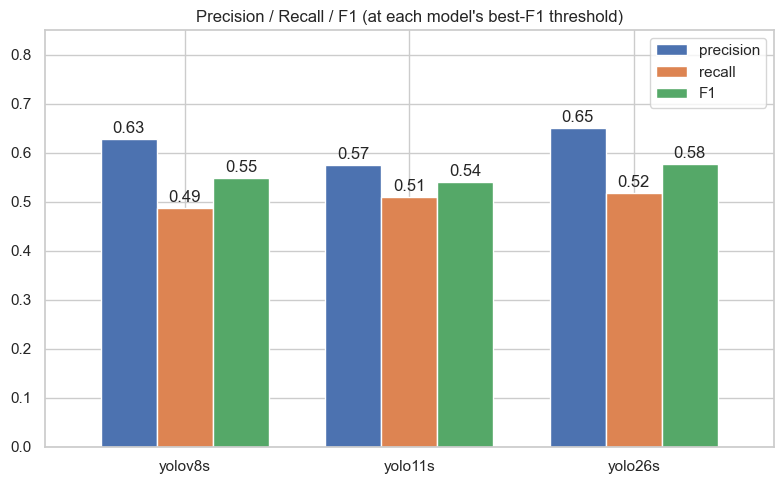

In [41]:
ax = final[["precision", "recall", "F1"]].plot(kind="bar", figsize=(8, 5), width=0.75, rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", padding=2)
ax.set_ylim(0, 0.85)
ax.set_xlabel("")
ax.set_title("Precision / Recall / F1 (at each model's best-F1 threshold)")
save_fig("03_prf1")

## Figure 4 (accuracy vs CPU latency; axes zoomed)

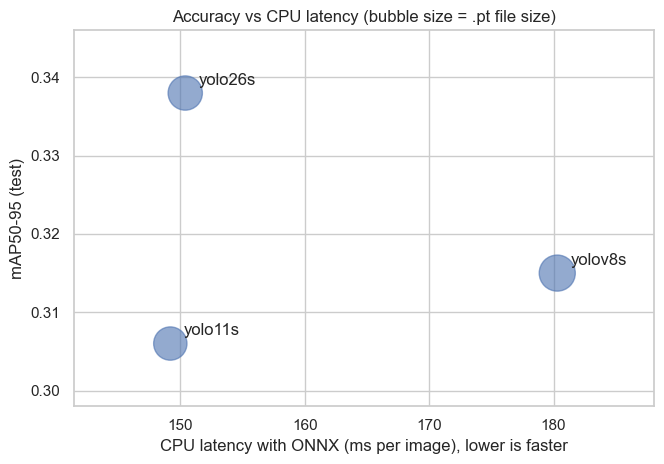

In [27]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(final["ONNX_CPU_ms"], final["mAP50-95"], s=final["weights_MB"] * 30, alpha=0.6)
for name, r in final.iterrows():
    ax.annotate(name, (r["ONNX_CPU_ms"], r["mAP50-95"]),
                textcoords="offset points", xytext=(10, 6))
ax.margins(0.25)
ax.set_xlabel("CPU latency with ONNX (ms per image), lower is faster")
ax.set_ylabel("mAP50-95 (test)")
ax.set_title("Accuracy vs CPU latency (bubble size = .pt file size)")
save_fig("04_accuracy_vs_speed")

## Figure 5 (matches at conf 0.25)

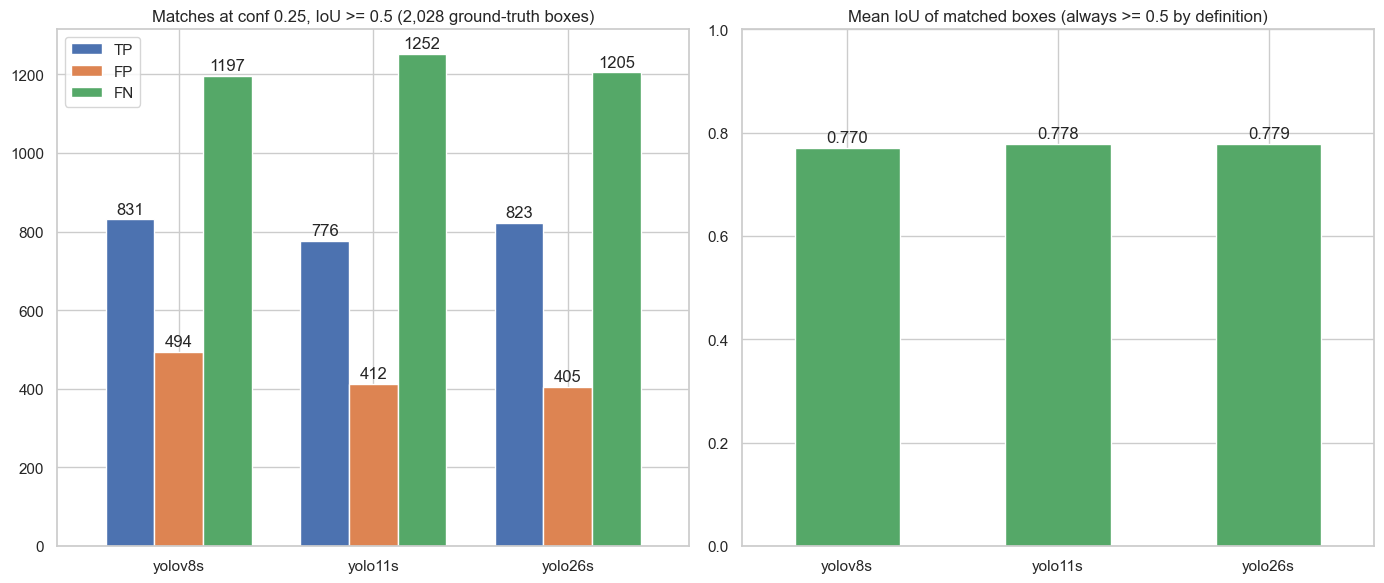

In [56]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

iou_df[["TP", "FP", "FN"]].plot(kind="bar", ax=ax[0], rot=0, width=0.75)
for c in ax[0].containers:
    ax[0].bar_label(c, fmt="%.0f", padding=2)
ax[0].set_title("Matches at conf 0.25, IoU >= 0.5 (2,028 ground-truth boxes)")
ax[0].set_xlabel("")

iou_df["mean_IoU_TP"].plot(kind="bar", ax=ax[1], rot=0, width=0.5, color="#55A868")
ax[1].bar_label(ax[1].containers[0], fmt="%.3f", padding=2)
ax[1].set_ylim(0, 1)
ax[1].set_title("Mean IoU of matched boxes (always >= 0.5 by definition)")
ax[1].set_xlabel("")

save_fig("05_matches_and_iou")

## Figure 6 (efficiency)

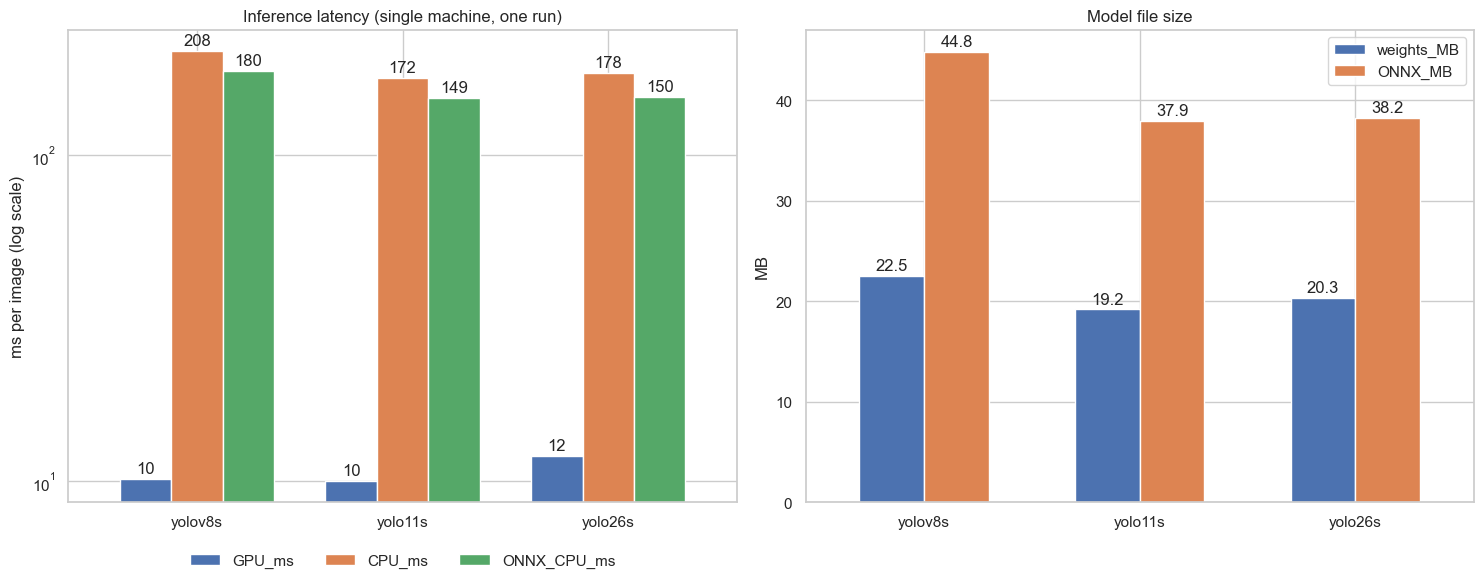

In [67]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

final[["GPU_ms", "CPU_ms", "ONNX_CPU_ms"]].plot(kind="bar", ax=ax[0], rot=0, width=0.75, logy=True)
for c in ax[0].containers:
    ax[0].bar_label(c, fmt="%.0f", padding=2)
ax[0].set_ylabel("ms per image (log scale)")
ax[0].set_title("Inference latency (single machine, one run)")
ax[0].set_xlabel("")
ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)

final[["weights_MB", "ONNX_MB"]].plot(kind="bar", ax=ax[1], rot=0, width=0.6)
for c in ax[1].containers:
    ax[1].bar_label(c, fmt="%.1f", padding=2)
ax[1].set_ylabel("MB")
ax[1].set_title("Model file size")
ax[1].set_xlabel("")

save_fig("06_efficiency")

In [49]:
import shutil
RUNS_DIR = "/kaggle/working/eval_runs"

shutil.make_archive("/kaggle/working/eval_final", "zip", "/kaggle/working", "eval_results")
shutil.make_archive("/kaggle/working/eval_plots", "zip", RUNS_DIR)
print(sorted(p.name for p in FIG.iterdir()))
print((OUT / "class_thresholds.json").exists())

['01_map_comparison.png', '02_per_class_heatmap.png', '03_prf1.png', '04_accuracy_vs_speed.png', '05_matches_and_iou.png', '06_efficiency.png']
True


## Results & Interpretation:

**Figure 1 (mAP).** YOLO26s leads on both metrics (mAP50 0.564, mAP50-95 0.338). YOLOv8s and YOLO11s differ by less than 0.01 and are not distinguishable from one run each.

**Figure 2 (per class).** The advantage of YOLO26s is concentrated in thin-crack classes (`crack`, `transverse`, `longitudinal`); on `pothole` and `alligator` the gap is about 0.01 or less. `block` scores highest for all models but has only 46 test instances, so differences there are noise.

**Figure 3 (P/R/F1).** Each model is evaluated at its own best-F1 threshold, so precision and recall are not strictly comparable across models.

**Figure 4 (accuracy vs CPU latency; axes zoomed).** YOLO26s is the most accurate at essentially the same latency as YOLO11s (150 vs 149 ms, within noise); YOLOv8s is both slower (about 20%) and less accurate.

**Figure 5 (matches at conf 0.25).** False negatives exceed true positives for every model (YOLO26s: 1,205 missed vs 823 found), so about 60% of ground-truth damage is missed at the default threshold. YOLO26s's advantage comes from fewer false positives (405 vs 494 / 412), not from more detections. Mean IoU of matched boxes is equal (0.77 to 0.78).

**Figure 6 (efficiency).** All models run at 10 to 12 ms on a T4 and 150 to 208 ms on CPU; ONNX is faster than PyTorch on CPU but its file is about twice the `.pt` size.

**Conclusion.** The figures confirm the validation-based choice of YOLO26s; at a common threshold (0.25) its F1 advantage over YOLOv8s is small (about 0.01), so the larger mAP gap partly reflects better confidence ranking across thresholds.

**Limits:** one run per model (no error bars); speed from a single shared cloud machine; small per-class test sets (`block` 46, `transverse` 58).